# PRACTICE 4 — DỰ BÁO CHUỖI THỜI GIAN ĐA BIẾN

In [1]:
import sys
import pandas as pd
import numpy as np

print("Python:", sys.version.split()[0])
print("Python executable:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Python: 3.12.15
Python executable: /Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_4/.venv/bin/python
Pandas: 3.1.1
NumPy: 2.5.5



## Phase 0 — Data Loading & Initial Inspection

### Mục tiêu
- Hiểu cấu trúc dữ liệu điện năng và thời tiết.
- Xác định các biến cần thiết cho bài toán.
- Kiểm tra chất lượng dữ liệu gốc.
- Chuẩn bị cơ sở cho việc xây dựng Data Contract.

### Bài toán
Sử dụng dữ liệu điện năng và thời tiết trong 24 giờ gần nhất để dự báo điện năng tiêu thụ ở giờ tiếp theo.

**Input:** Load, Temperature, Humidity, Wind Speed.

**Target:** Load tại thời điểm tiếp theo.

**Models:** VAR, XGBoost, LSTM.


In [7]:

from pathlib import Path
import pandas as pd

# Xác định đường dẫn dữ liệu gốc
thu_muc = Path.cwd().resolve()

cac_duong_dan = [
    thu_muc / "datasets/raw",
    thu_muc.parent / "datasets/raw",
    thu_muc / "total_practice/Practice_4/datasets/raw"
]

thu_muc_raw = next(
    (p for p in cac_duong_dan
     if (p / "energy_dataset.csv").is_file()
     and (p / "weather_features.csv").is_file()),
    None
)

if thu_muc_raw is None:
    raise FileNotFoundError("Không tìm thấy dữ liệu gốc")

# Đọc hai tập dữ liệu
df_dien = pd.read_csv(thu_muc_raw / "energy_dataset.csv")
df_thoi_tiet = pd.read_csv(thu_muc_raw / "weather_features.csv")

# Kiểm tra cấu trúc dữ liệu
print("Kích thước điện năng:", df_dien.shape)
print("Kích thước thời tiết:", df_thoi_tiet.shape)

print("\nDữ liệu điện năng:")
display(df_dien[["time", "total load actual"]].head(3))

print("Dữ liệu thời tiết:")
display(df_thoi_tiet[
    ["dt_iso", "city_name", "temp", "humidity", "wind_speed"]
].head(3))


Kích thước điện năng: (35064, 29)
Kích thước thời tiết: (178396, 17)

Dữ liệu điện năng:


,time,total load actual
0,2015-01-01 00:00:00+01:00,25385.0
1,2015-01-01 01:00:00+01:00,24382.0
2,2015-01-01 02:00:00+01:00,22734.0


Dữ liệu thời tiết:


,dt_iso,city_name,temp,humidity,wind_speed
0,2015-01-01 00:00:00+01:00,Valencia,270.475,77,1
1,2015-01-01 01:00:00+01:00,Valencia,270.475,77,1
2,2015-01-01 02:00:00+01:00,Valencia,269.686,78,0


### **Kiểm tra chất lượng dữ liệu**


In [8]:

# Các biến cần kiểm tra
cot_dien = ["time", "total load actual"]
cot_thoi_tiet = [
    "dt_iso", "city_name", "temp", "humidity", "wind_speed"
]

# Chuyển timestamp để kiểm tra, không thay đổi dữ liệu gốc
tg_dien = pd.to_datetime(df_dien["time"], utc=True, errors="coerce")
tg_thoi_tiet = pd.to_datetime(
    df_thoi_tiet["dt_iso"], utc=True, errors="coerce"
)

thanh_pho = df_thoi_tiet["city_name"].str.strip()
madrid = thanh_pho == "Madrid"

# 1. Kiểm tra giá trị thiếu
print("=== GIÁ TRỊ THIẾU ===")
print("Điện năng:\n", df_dien[cot_dien].isna().sum())
print("Thời tiết:\n", df_thoi_tiet[cot_thoi_tiet].isna().sum())

# 2. Kiểm tra thời gian và trùng lặp
print("\n=== CHẤT LƯỢNG TIMESTAMP ===")
print("Timestamp điện không hợp lệ:", tg_dien.isna().sum())
print("Timestamp thời tiết không hợp lệ:", tg_thoi_tiet.isna().sum())
print("Timestamp điện trùng:", tg_dien.duplicated().sum())

print("Timestamp Madrid trùng:",
      tg_thoi_tiet[madrid].duplicated().sum())

print("Khoảng thời gian điện:", tg_dien.min(), "→", tg_dien.max())

# 3. Kiểm tra tính liên tục theo giờ
khoang_cach = tg_dien.sort_values().diff().dropna()
print("Số khoảng cách khác 1 giờ:",
      (khoang_cach != pd.Timedelta(hours=1)).sum())

# 4. Kiểm tra độ phủ dữ liệu Madrid
moc_dien = pd.DatetimeIndex(tg_dien.dropna().unique())
moc_madrid = pd.DatetimeIndex(
    tg_thoi_tiet[madrid].dropna().unique()
)

print("\n=== DỮ LIỆU MADRID ===")
print("Số timestamp duy nhất:", len(moc_madrid))
print("Số giờ điện không có thời tiết Madrid:",
      len(moc_dien.difference(moc_madrid)))


=== GIÁ TRỊ THIẾU ===
Điện năng:
 time                  0
total load actual    36
dtype: int64
Thời tiết:
 dt_iso        0
city_name     0
temp          0
humidity      0
wind_speed    0
dtype: int64

=== CHẤT LƯỢNG TIMESTAMP ===
Timestamp điện không hợp lệ: 0
Timestamp thời tiết không hợp lệ: 0
Timestamp điện trùng: 0
Timestamp Madrid trùng: 1203
Khoảng thời gian điện: 2014-12-31 23:00:00+00:00 → 2018-12-31 22:00:00+00:00
Số khoảng cách khác 1 giờ: 0

=== DỮ LIỆU MADRID ===
Số timestamp duy nhất: 35064
Số giờ điện không có thời tiết Madrid: 0


# PHASE 1 - DATA PREPARATION

In [10]:

# 1. Chọn các cột cần thiết
dien = df_dien[["time", "total load actual"]].copy()
thoi_tiet = df_thoi_tiet[
    ["dt_iso", "city_name", "temp", "humidity", "wind_speed"]
].copy()

# 2. Chuẩn hóa tên cột và thời gian
dien = dien.rename(columns={"total load actual": "load"})
dien["time"] = pd.to_datetime(dien["time"], utc=True)

thoi_tiet = thoi_tiet.rename(columns={"temp": "temperature"})
thoi_tiet["time"] = pd.to_datetime(thoi_tiet["dt_iso"], utc=True)
thoi_tiet["city_name"] = thoi_tiet["city_name"].str.strip()

# 3. Chọn thời tiết Madrid
madrid = thoi_tiet.loc[
    thoi_tiet["city_name"] == "Madrid",
    ["time", "temperature", "humidity", "wind_speed"]
].copy()

# 4. Kiểm tra các timestamp trùng có giá trị khác nhau hay không
bien_thoi_tiet = ["temperature", "humidity", "wind_speed"]

trung_khac_gia_tri = (
    madrid.groupby("time")[bien_thoi_tiet]
    .nunique(dropna=False)
    .gt(1)
    .any(axis=1)
)

if trung_khac_gia_tri.any():
    raise ValueError("Có timestamp Madrid trùng với giá trị thời tiết khác nhau")

# Chỉ loại bản ghi trùng khi giá trị thời tiết giống nhau
madrid = madrid.drop_duplicates(subset=["time"])

# 5. Đổi nhiệt độ từ Kelvin sang Celsius
madrid["temperature"] = madrid["temperature"] - 273.15

# 6. Kiểm tra timestamp điện năng trước khi ghép
if dien["time"].isna().any() or dien["time"].duplicated().any():
    raise ValueError("Timestamp điện năng không hợp lệ hoặc bị trùng")

# 7. Ghép dữ liệu theo thời gian
du_lieu = pd.merge(
    dien,
    madrid,
    on="time",
    how="left",
    validate="one_to_one"
)

# 8. Sắp xếp và thiết lập tần suất theo giờ
du_lieu = (
    du_lieu.set_index("time")
    .sort_index()
    .asfreq("h")
)

print("Đã chuẩn bị và ghép dữ liệu thành công.")
display(du_lieu.head(3))

Đã chuẩn bị và ghép dữ liệu thành công.


,load,temperature,humidity,wind_speed
time,,,,
2014-12-31 23:00:00+00:00,25385.0,-5.825,63,1
2015-01-01 00:00:00+00:00,24382.0,-5.825,63,1
2015-01-01 01:00:00+00:00,22734.0,-6.964,64,1


In [11]:

# Kiểm tra chất lượng dữ liệu sau khi ghép
print("=== KẾT QUẢ DATA PREPARATION ===")

print("Kích thước:", du_lieu.shape)
print("Các biến:", du_lieu.columns.tolist())
print("Khoảng thời gian:", du_lieu.index.min(), "→", du_lieu.index.max())

print("\nGiá trị thiếu:")
print(du_lieu.isna().sum())

print("\nTimestamp trùng:", du_lieu.index.duplicated().sum())

khoang_cach = du_lieu.index.to_series().diff().dropna()
print("Khoảng cách khác 1 giờ:",
      (khoang_cach != pd.Timedelta(hours=1)).sum())

# Kiểm tra các điều kiện bắt buộc
assert du_lieu.columns.tolist() == [
    "load", "temperature", "humidity", "wind_speed"
]

assert du_lieu.index.is_monotonic_increasing
assert not du_lieu.index.has_duplicates
assert du_lieu.index.tz is not None
assert len(du_lieu) >= 24

print("\nKiểm tra cấu trúc: ĐẠT")


=== KẾT QUẢ DATA PREPARATION ===
Kích thước: (35064, 4)
Các biến: ['load', 'temperature', 'humidity', 'wind_speed']
Khoảng thời gian: 2014-12-31 23:00:00+00:00 → 2018-12-31 22:00:00+00:00

Giá trị thiếu:
load           36
temperature     0
humidity        0
wind_speed      0
dtype: int64

Timestamp trùng: 0
Khoảng cách khác 1 giờ: 0

Kiểm tra cấu trúc: ĐẠT


# PHASE 2 - TEMPORAL SPLIT 70/15/15

In [12]:
tong_so_mau = len(du_lieu)

moc_train = int(tong_so_mau * 0.70)
moc_validation = int(tong_so_mau * 0.85)

train_df = du_lieu.iloc[:moc_train].copy()

val_df = du_lieu.iloc[moc_train:moc_validation].copy()

test_df = du_lieu.iloc[moc_validation:].copy()

print("=== KẾT QUẢ CHIA DỮ LIỆU ===")
print("Tổng số quan sát: {tong_so_mau:,}")
print(f"Train: {len(train_df):,} ({len(train_df)/tong_so_mau:.2%})")
print(f"Validation: {len(val_df):,} ({len(val_df)/tong_so_mau:.2%})")
print(f"Test: {len(test_df):,} ({len(test_df)/tong_so_mau:.2%})")

print("\n=== KHOẢNG THỜI GIAN ===")

for ten, tap in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"{ten}: {tap.index.min()} → {tap.index.max()}")


=== KẾT QUẢ CHIA DỮ LIỆU ===
Tổng số quan sát: {tong_so_mau:,}
Train: 24,544 (70.00%)
Validation: 5,260 (15.00%)
Test: 5,260 (15.00%)

=== KHOẢNG THỜI GIAN ===
Train: 2014-12-31 23:00:00+00:00 → 2017-10-19 14:00:00+00:00
Validation: 2017-10-19 15:00:00+00:00 → 2018-05-26 18:00:00+00:00
Test: 2018-05-26 19:00:00+00:00 → 2018-12-31 22:00:00+00:00


In [13]:

# Kiểm tra số lượng dữ liệu được bảo toàn
assert len(train_df) + len(val_df) + len(test_df) == len(du_lieu)

# Kiểm tra các tập không chồng lấn thời gian
assert train_df.index.max() < val_df.index.min()
assert val_df.index.max() < test_df.index.min()

# Kiểm tra các tập đều được sắp xếp tăng dần
assert train_df.index.is_monotonic_increasing
assert val_df.index.is_monotonic_increasing
assert test_df.index.is_monotonic_increasing

# Kiểm tra các tập không bị trùng timestamp
assert not train_df.index.has_duplicates
assert not val_df.index.has_duplicates
assert not test_df.index.has_duplicates

# Kiểm tra ranh giới giữa các tập cách nhau đúng 1 giờ
assert val_df.index.min() - train_df.index.max() == pd.Timedelta(hours=1)
assert test_df.index.min() - val_df.index.max() == pd.Timedelta(hours=1)

print("Tất cả kiểm tra Temporal Split: ĐẠT")


Tất cả kiểm tra Temporal Split: ĐẠT


# PHASE 3 - EDA 

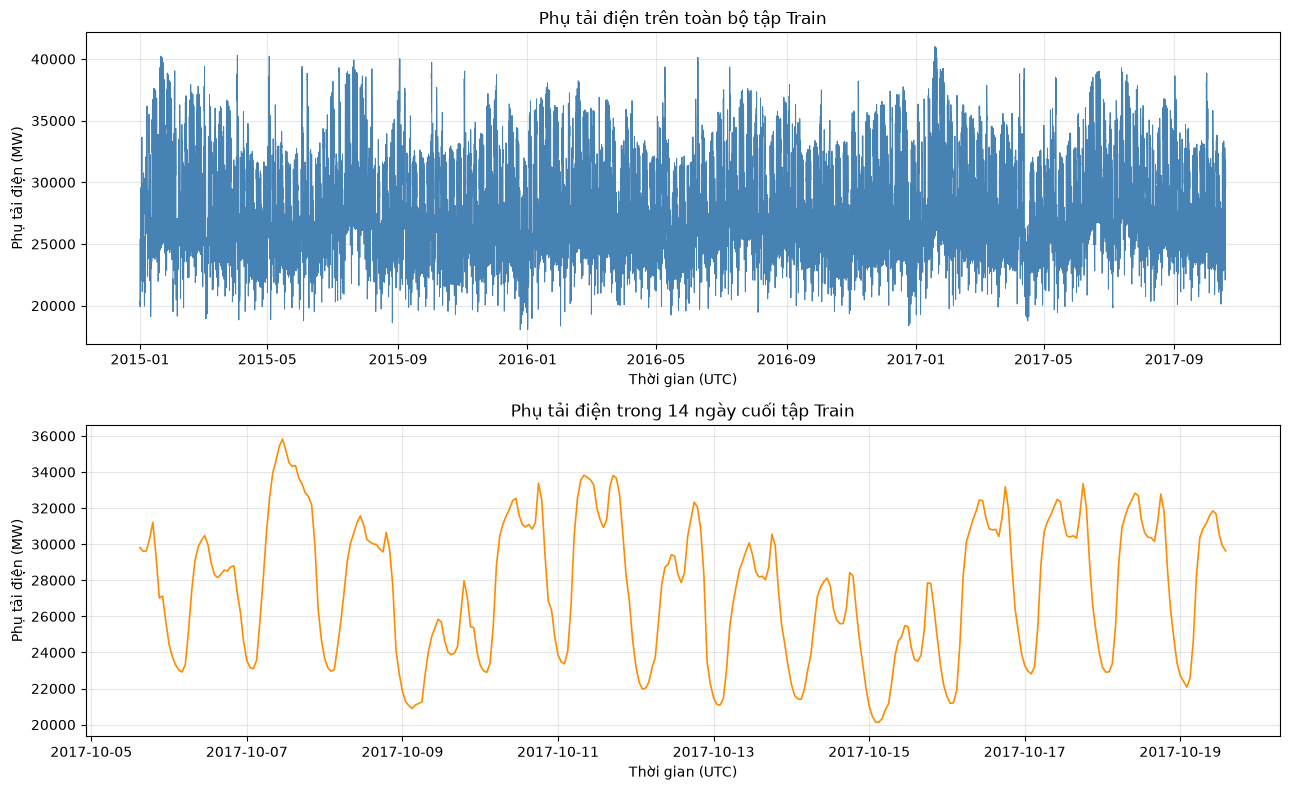

In [14]:
import matplotlib.pyplot as plt

du_lieu_eda = train_df.copy()

phu_tai = du_lieu_eda["load"]
phu_tai_14_ngay = phu_tai.iloc[-24 * 14:]

# Tao 2 bieu do
fig, axes = plt.subplots(2, 1, figsize=(13, 8))

# Bieu do 1
axes[0].plot(
    phu_tai.index,
    phu_tai.values,
    color="steelblue",
    linewidth=0.7
)

axes[0].set_title("Phụ tải điện trên toàn bộ tập Train")
axes[0].set_xlabel("Thời gian (UTC)")
axes[0].set_ylabel("Phụ tải điện (MW)")
axes[0].grid(alpha=0.3)

# Bieu do 2
axes[1].plot(
    phu_tai_14_ngay.index,
    phu_tai_14_ngay.values,
    color="darkorange",
    linewidth=1.2
)

axes[1].set_title("Phụ tải điện trong 14 ngày cuối tập Train")
axes[1].set_xlabel("Thời gian (UTC)")
axes[1].set_ylabel("Phụ tải điện (MW)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

/var/folders/bk/ywq0gfcd6qv8bhfb_0y9_0000000gq/T/ipykernel_97832/2724656309.py:5: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  theo_ngay = phu_tai.groupby(phu_tai.index.dayofweek).mean()


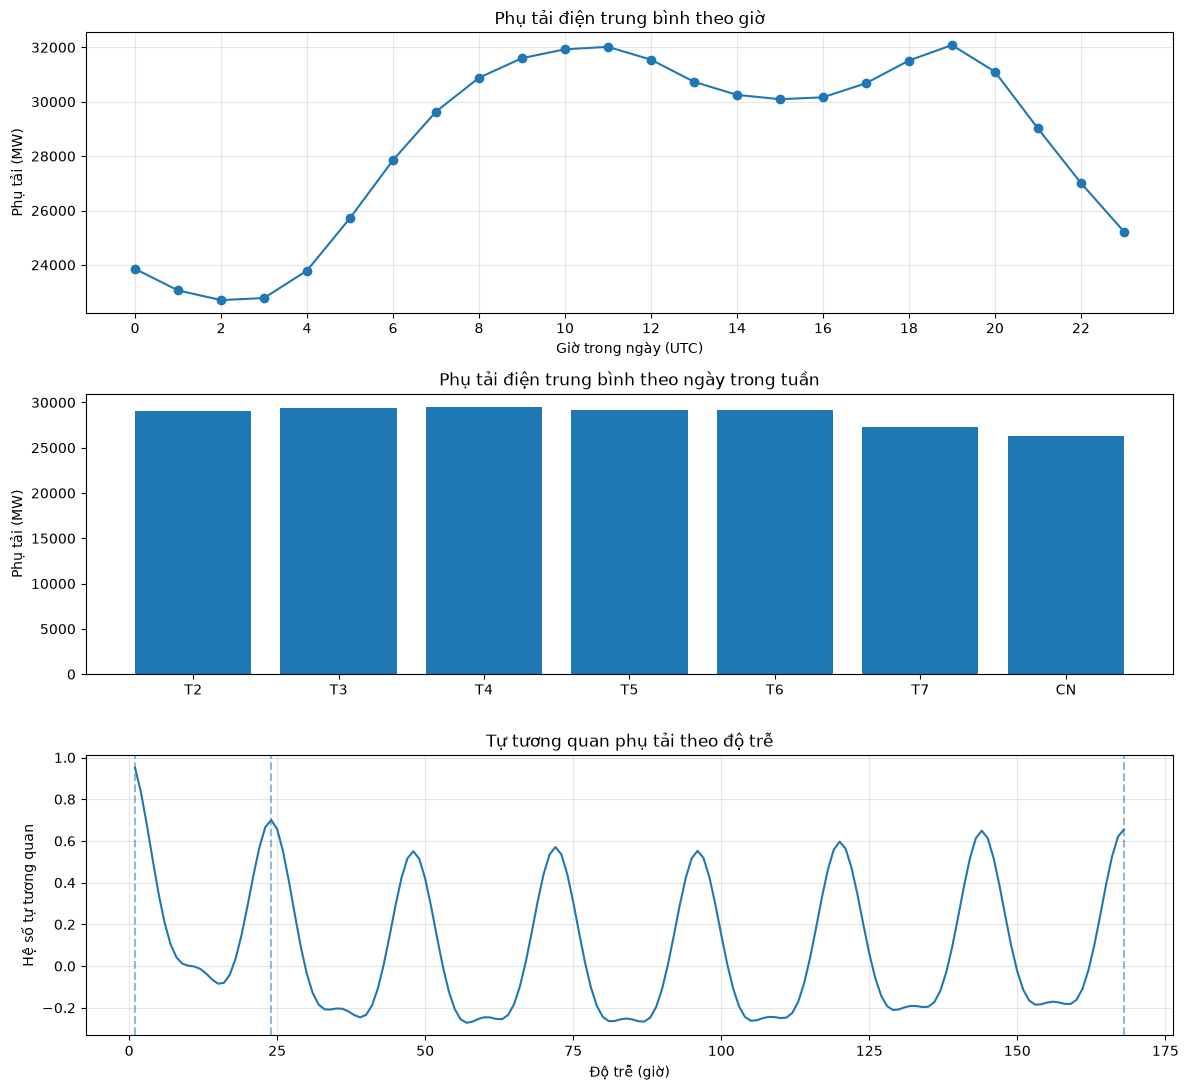

Lag 1: 0.9509
Lag 24: 0.7004
Lag 168: 0.6546


In [15]:
du_lieu_eda = train_df.copy()
phu_tai = du_lieu_eda["load"]

theo_gio = phu_tai.groupby(phu_tai.index.hour).mean()
theo_ngay = phu_tai.groupby(phu_tai.index.dayofweek).mean()

# Tính tự tương quan từ lag 1 đến lag 168
cac_lag = range(1, 169)
tu_tuong_quan = [
    phu_tai.autocorr(lag=lag) for lag in cac_lag
]

fig, axes = plt.subplots(3, 1, figsize=(12, 11))

axes[0].plot(theo_gio.index, theo_gio.values, marker="o")
axes[0].set_title("Phụ tải điện trung bình theo giờ")
axes[0].set_xlabel("Giờ trong ngày (UTC)")
axes[0].set_ylabel("Phụ tải (MW)")
axes[0].set_xticks(range(0, 24, 2))
axes[0].grid(alpha=0.3)

axes[1].bar(theo_ngay.index, theo_ngay.values)
axes[1].set_title("Phụ tải điện trung bình theo ngày trong tuần")
axes[1].set_ylabel("Phụ tải (MW)")
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(["T2", "T3", "T4", "T5", "T6", "T7", "CN"])

axes[2].plot(cac_lag, tu_tuong_quan)
axes[2].set_title("Tự tương quan phụ tải theo độ trễ")
axes[2].set_xlabel("Độ trễ (giờ)")
axes[2].set_ylabel("Hệ số tự tương quan")

for lag in [1, 24, 168]:
    axes[2].axvline(lag, linestyle="--", alpha=0.5)

axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# In các độ trễ quan trọng
for lag in [1, 24, 168]:
    print(f"Lag {lag}: {phu_tai.autocorr(lag=lag):.4f}")

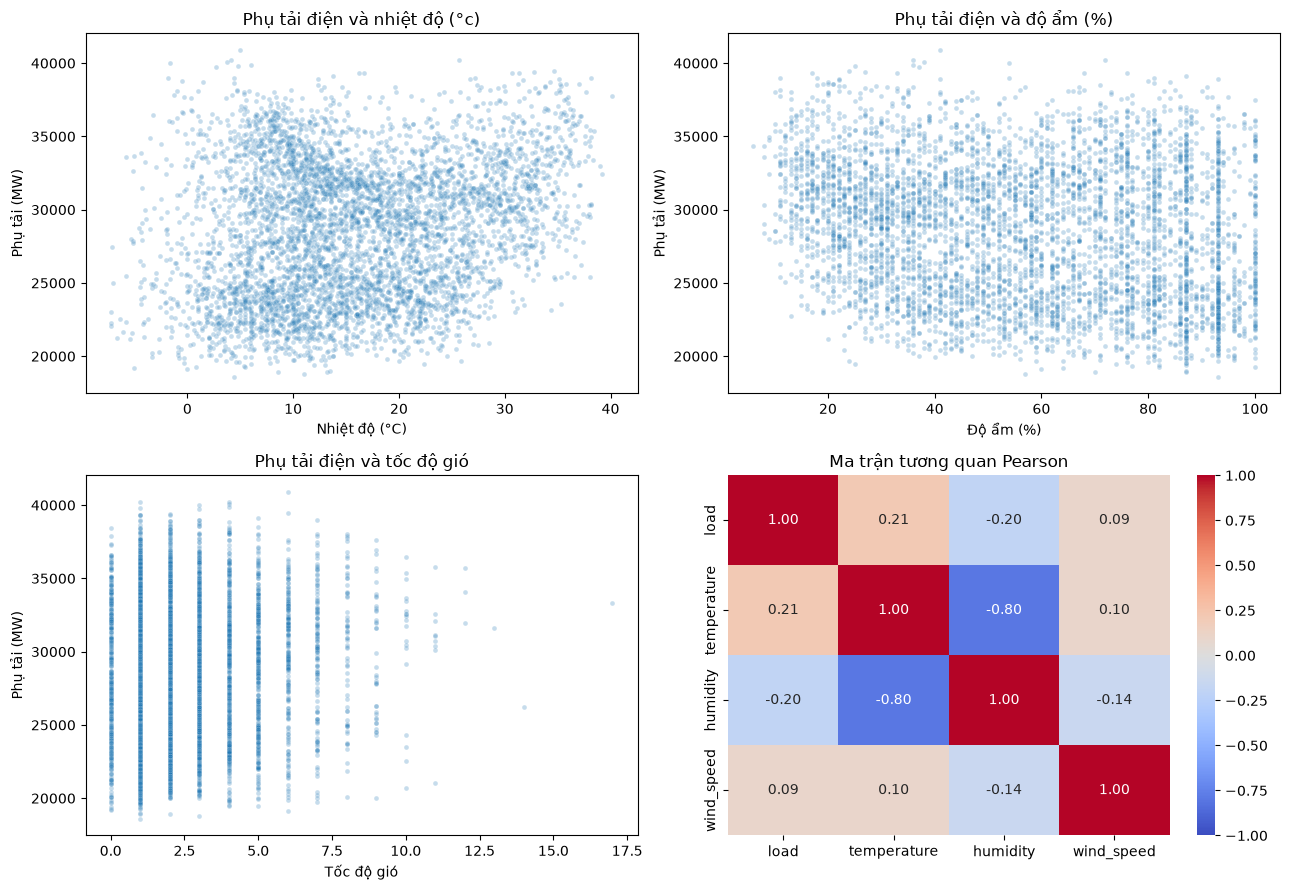

=== TƯƠNG QUAN VỚI PHỤ TẢI ĐIỆN ===
temperature    0.214180
humidity      -0.195269
wind_speed     0.094189
Name: load, dtype: float64


In [19]:
import seaborn as sns

cac_bien = ["load", "temperature", "humidity", "wind_speed"]
du_lieu_tuong_quan = du_lieu_eda[cac_bien]

mau_ve = du_lieu_tuong_quan.dropna().sample(
    n=min(5000, len(du_lieu_tuong_quan.dropna())),
    random_state=42
)

# Tinh ma trận tương quan
ma_tran_tuong_quan = du_lieu_tuong_quan.corr()

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

cac_bien_thoi_tiet = ["temperature", "humidity", "wind_speed"]
ten_bien = ["Nhiệt độ (°C)", "Độ ẩm (%)", "Tốc độ gió"]

for ax, bien, ten in zip(
    axes.flat[:3], cac_bien_thoi_tiet, ten_bien
):
    sns.scatterplot(
        data=mau_ve,
        x=bien,
        y="load",
        ax=ax,
        alpha=0.25,
        s=12
    )
    ax.set_title(f"Phụ tải điện và {ten.lower()}")
    ax.set_xlabel(ten)
    ax.set_ylabel("Phụ tải (MW)")

sns.heatmap(
    ma_tran_tuong_quan,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[1, 1]
)

axes[1, 1].set_title("Ma trận tương quan Pearson")

plt.tight_layout()
plt.show()

# Hệ số tương quan giữa phụ tải và thời tiết
print("=== TƯƠNG QUAN VỚI PHỤ TẢI ĐIỆN ===")
print(
    ma_tran_tuong_quan["load"]
    .drop("load")
    .sort_values(key=abs, ascending=False)
)


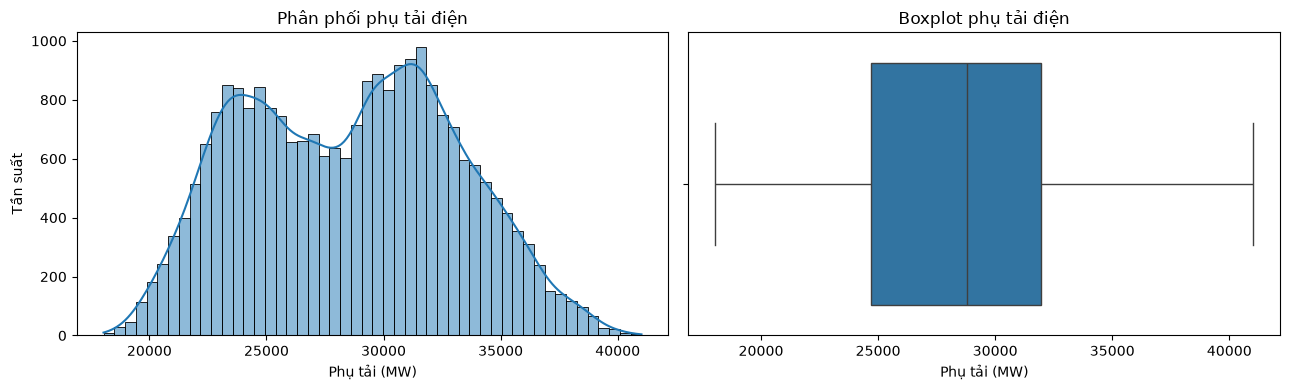

=== THỐNG KÊ PHỤ TẢI ĐIỆN ===
Giá trị thiếu trong Train: 32
Trung bình: 28551.50 MW
Trung vị: 28811.50 MW
Độ lệch chuẩn: 4535.26 MW
Số điểm ngoài ngưỡng IQR: 0
Tỷ lệ ngoài ngưỡng IQR: 0.00%


In [20]:

# 1. Lấy phụ tải hợp lệ trong tập Train
phu_tai_hop_le = du_lieu_eda["load"].dropna()

# 2. Tính các ngưỡng phát hiện ngoại lệ theo IQR
q1 = phu_tai_hop_le.quantile(0.25)
q3 = phu_tai_hop_le.quantile(0.75)
iqr = q3 - q1

nguong_duoi = q1 - 1.5 * iqr
nguong_tren = q3 + 1.5 * iqr

ngoai_le = (
    (phu_tai_hop_le < nguong_duoi) |
    (phu_tai_hop_le > nguong_tren)
)

# 3. Vẽ hai biểu đồ
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    phu_tai_hop_le,
    bins=50,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Phân phối phụ tải điện")
axes[0].set_xlabel("Phụ tải (MW)")
axes[0].set_ylabel("Tần suất")

sns.boxplot(
    x=phu_tai_hop_le,
    ax=axes[1]
)

axes[1].set_title("Boxplot phụ tải điện")
axes[1].set_xlabel("Phụ tải (MW)")

plt.tight_layout()
plt.show()

# 4. Thống kê các giá trị cần chú ý
print("=== THỐNG KÊ PHỤ TẢI ĐIỆN ===")
print(f"Giá trị thiếu trong Train: {du_lieu_eda['load'].isna().sum()}")
print(f"Trung bình: {phu_tai_hop_le.mean():.2f} MW")
print(f"Trung vị: {phu_tai_hop_le.median():.2f} MW")
print(f"Độ lệch chuẩn: {phu_tai_hop_le.std():.2f} MW")
print(f"Số điểm ngoài ngưỡng IQR: {ngoai_le.sum()}")
print(f"Tỷ lệ ngoài ngưỡng IQR: {ngoai_le.mean():.2%}")


# PHASE 4 - Preprocessing & Feature Engineẻing

In [21]:

# 1. Xác định các biến đầu vào
cac_bien = ["load", "temperature", "humidity", "wind_speed"]

# 2. Giữ nguyên target thực tế
y_train_goc = train_df["load"].copy()
y_val_goc = val_df["load"].copy()

# 3. Xử lý missing trong đầu vào Train bằng Forward Fill
train_input = train_df[cac_bien].copy().ffill()

# Không dùng dữ liệu tương lai để điền giá trị đầu chuỗi
if train_input.isna().any().any():
    raise ValueError("Train còn giá trị thiếu không thể xử lý bằng Forward Fill")

# 4. Xử lý Validation theo thứ tự thời gian
# Những giờ đầu Validation có thể sử dụng lịch sử cuối Train
val_input = val_df[cac_bien].copy().ffill()
val_input = val_input.fillna(train_input.iloc[-1])

# 5. Kiểm tra số lượng missing
print("=== XỬ LÝ GIÁ TRỊ THIẾU ===")
print("Missing Train trước xử lý:", train_df[cac_bien].isna().sum().sum())
print("Missing Train sau xử lý:", train_input.isna().sum().sum())

print("Missing Validation trước xử lý:", val_df[cac_bien].isna().sum().sum())
print("Missing Validation sau xử lý:", val_input.isna().sum().sum())

print("\nTarget thiếu trong Train:", y_train_goc.isna().sum())
print("Target thiếu trong Validation:", y_val_goc.isna().sum())


=== XỬ LÝ GIÁ TRỊ THIẾU ===
Missing Train trước xử lý: 32
Missing Train sau xử lý: 0
Missing Validation trước xử lý: 2
Missing Validation sau xử lý: 0

Target thiếu trong Train: 32
Target thiếu trong Validation: 2


In [24]:
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# 1. Khởi tạo bộ chuẩn hóa
bo_chuan_hoa = StandardScaler()

# 2. Học tham số trên Train
train_scaled_array = bo_chuan_hoa.fit_transform(train_input)

# 3. Chuẩn hóa Validation bằng tham số của Train
val_scaled_array = bo_chuan_hoa.transform(val_input)

# 4. Chuyển kết quả về DataFrame, giữ nguyên thời gian
train_scaled = pd.DataFrame(
    train_scaled_array,
    index=train_input.index,
    columns=cac_bien
)

val_scaled = pd.DataFrame(
    val_scaled_array,
    index=val_input.index,
    columns=cac_bien
)

# 5. Kiểm tra dữ liệu sau chuẩn hóa
assert np.isfinite(train_scaled.to_numpy()).all()
assert np.isfinite(val_scaled.to_numpy()).all()

assert train_scaled.index.equals(train_df.index)
assert val_scaled.index.equals(val_df.index)

assert y_train_goc.equals(train_df["load"])
assert y_val_goc.equals(val_df["load"])

print("=== KẾT QUẢ CHUẨN HÓA ===")
print("Train:", train_scaled.shape)
print("Validation:", val_scaled.shape)

print("\nTrung bình các biến sau chuẩn hóa Train:")
print(train_scaled.mean().round(4))

print("\nĐộ lệch chuẩn các biến sau chuẩn hóa Train:")
print(train_scaled.std(ddof=0).round(4))

print("\nKiểm tra Preprocessing: ĐẠT")


=== KẾT QUẢ CHUẨN HÓA ===
Train: (24544, 4)
Validation: (5260, 4)

Trung bình các biến sau chuẩn hóa Train:
load          -0.0
temperature    0.0
humidity       0.0
wind_speed    -0.0
dtype: float64

Độ lệch chuẩn các biến sau chuẩn hóa Train:
load           1.0
temperature    1.0
humidity       1.0
wind_speed     1.0
dtype: float64

Kiểm tra Preprocessing: ĐẠT


# Phase 5 — Feature Engineering

In [26]:
import numpy as np
import pandas as pd

so_gio_lich_su = 24
cac_bien = ["load", "temperature", "humidity", "wind_speed"]

du_lieu_scaled = pd.concat([train_scaled, val_scaled])
nhan_goc = pd.concat([y_train_goc, y_val_goc])

# Ham tao cua so truot
def tao_cua_so(du_lieu, nhan, cac_moc_du_bao, kich_thuoc=24):
    danh_sach_X = []
    danh_sach_y = []
    danh_sach_thoi_gian = []

    vi_tri_du_bao = du_lieu.index.get_indexer(cac_moc_du_bao)

    if (vi_tri_du_bao < 0).any():
        raise ValueError("Có thời điểm dự báo không tồn tại trong dữ liệu")

    for vi_tri in vi_tri_du_bao:

        # Cần đủ 24 giờ lịch sử
        if vi_tri < kich_thuoc:
            continue

        # Không sử dụng target đã bị thiếu trong dữ liệu gốc
        if pd.isna(nhan.iloc[vi_tri]):
            continue

        # Lấy các quan sát trước thời điểm cần dự báo
        cua_so = du_lieu.iloc[
            vi_tri - kich_thuoc:vi_tri
        ][cac_bien].to_numpy()

        if not np.isfinite(cua_so).all():
            continue

        danh_sach_X.append(cua_so)
        danh_sach_y.append(nhan.iloc[vi_tri])
        danh_sach_thoi_gian.append(du_lieu.index[vi_tri])

    return (
        np.asarray(danh_sach_X),
        np.asarray(danh_sach_y),
        pd.DatetimeIndex(danh_sach_thoi_gian)
    )

X_train, y_train, tg_train = tao_cua_so(
    du_lieu_scaled,
    nhan_goc,
    train_scaled.index,
    so_gio_lich_su
)

X_val, y_val, tg_val = tao_cua_so(
    du_lieu_scaled,
    nhan_goc,
    val_scaled.index,
    so_gio_lich_su
)

print("=== DỮ LIỆU LSTM ===")
print("X Train:", X_train.shape)
print("y Train:", y_train.shape)
print("X Validation:", X_val.shape)
print("y Validation:", y_val.shape)


=== DỮ LIỆU LSTM ===
X Train: (24488, 24, 4)
y Train: (24488,)
X Validation: (5258, 24, 4)
y Validation: (5258,)


In [27]:
# Tạo danh sách tên của 96 lag features
ten_cot_lag = [
    f"{bien}_lag_{lag}"
    for lag in range(24, 0, -1)
    for bien in cac_bien
]

# Hàm chuyển cửa sổ thành dữ liệu dạng bảng
def tao_dac_trung_xgboost(X, thoi_gian):

    # Chuyển dữ liệu 3D thành 2D
    X_phang = X.reshape(X.shape[0], -1)

    bang = pd.DataFrame(
        X_phang,
        columns=ten_cot_lag,
        index=thoi_gian
    )

    # Lấy lịch sử phụ tải trong từng cửa sổ
    lich_su_load = X[:, :, 0]

    # Trung bình phụ tải của 6 giờ gần nhất
    bang["load_rolling_mean_6"] = (
        lich_su_load[:, -6:].mean(axis=1)
    )

    # Độ lệch chuẩn phụ tải trong 24 giờ
    bang["load_rolling_std_24"] = (
        lich_su_load.std(axis=1, ddof=0)
    )

    # Mức thay đổi giữa quan sát đầu và cuối cửa sổ
    bang["load_change_window"] = (
        lich_su_load[:, -1] - lich_su_load[:, 0]
    )

    return bang

# Tạo dữ liệu XGBoost
X_train_xgb = tao_dac_trung_xgboost(X_train, tg_train)
X_val_xgb = tao_dac_trung_xgboost(X_val, tg_val)

print("=== DỮ LIỆU XGBOOST ===")
print("Train:", X_train_xgb.shape)
print("Validation:", X_val_xgb.shape)

display(X_train_xgb.head(3))


=== DỮ LIỆU XGBOOST ===
Train: (24488, 99)
Validation: (5258, 99)


,load_lag_24,temperature_lag_24,humidity_lag_24,wind_speed_lag_24,load_lag_23,temperature_lag_23,humidity_lag_23,wind_speed_lag_23,load_lag_22,temperature_lag_22,...,temperature_lag_2,humidity_lag_2,wind_speed_lag_2,load_lag_1,temperature_lag_1,humidity_lag_1,wind_speed_lag_1,load_rolling_mean_6,load_rolling_std_24,load_change_window
2015-01-01 23:00:00+00:00,-0.698092,-2.282955,0.250706,-0.734667,-0.919192,-2.282955,0.250706,-0.734667,-1.282474,-2.403543,...,-2.119807,0.250706,-0.734667,-0.386612,-2.303706,0.290767,-0.734667,-0.089278,0.658219,0.311479
2015-01-02 00:00:00+00:00,-0.919192,-2.282955,0.250706,-0.734667,-1.282474,-2.403543,0.290767,-0.734667,-1.601669,-2.403543,...,-2.303706,0.290767,-0.734667,-0.326653,-2.303706,0.290767,-0.734667,-0.066389,0.670012,0.592538
2015-01-02 01:00:00+00:00,-1.282474,-2.403543,0.290767,-0.734667,-1.601669,-2.403543,0.290767,-0.734667,-1.826957,-2.403543,...,-2.303706,0.290767,-0.734667,-0.797289,-2.303706,0.290767,-0.734667,-0.179731,0.671147,0.485185


In [28]:

# 1. Kiểm tra kích thước đầu vào LSTM
assert X_train.ndim == 3
assert X_val.ndim == 3

assert X_train.shape[1:] == (24, 4)
assert X_val.shape[1:] == (24, 4)

# 2. Kiểm tra số mẫu và nhãn
assert len(X_train) == len(y_train) == len(tg_train)
assert len(X_val) == len(y_val) == len(tg_val)

# 3. Kiểm tra XGBoost có cùng số mẫu
assert len(X_train_xgb) == len(y_train)
assert len(X_val_xgb) == len(y_val)

# 4. Kiểm tra dữ liệu đầu vào và target hợp lệ
assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()
assert np.isfinite(y_train).all()
assert np.isfinite(y_val).all()

# 5. Kiểm tra target thuộc đúng tập thời gian
assert tg_train.isin(train_df.index).all()
assert tg_val.isin(val_df.index).all()

# 6. Kiểm tra mục tiêu không bị thay bằng giá trị nội suy
assert np.array_equal(
    y_train,
    y_train_goc.loc[tg_train].to_numpy()
)
assert np.array_equal(
    y_val,
    y_val_goc.loc[tg_val].to_numpy()
)

# 7. Kiểm tra không có dữ liệu tương lai trong cửa sổ đầu tiên
assert tg_train[0] - du_lieu_scaled.index[0] == pd.Timedelta(hours=24)

print("Kiểm tra Feature Engineering: ĐẠT")
print("Số mẫu Train hợp lệ:", len(y_train))
print("Số mẫu Validation hợp lệ:", len(y_val))
print("Số đặc trưng XGBoost:", X_train_xgb.shape[1])


Kiểm tra Feature Engineering: ĐẠT
Số mẫu Train hợp lệ: 24488
Số mẫu Validation hợp lệ: 5258
Số đặc trưng XGBoost: 99


# PHASE 6 - Baseline Forecasting
Xây dựng hai phương pháp dự báo cơ sở để làm mốc so snahs với VAR, XGBoost, LSTM.  
Sử dụng Navie, Seasonal Naive

In [33]:

import numpy as np
import pandas as pd

phu_tai_goc = pd.concat([
    y_train_goc,
    y_val_goc
]).sort_index()

assert not phu_tai_goc.index.has_duplicates
assert (
    phu_tai_goc.index.to_series().diff().dropna()
    == pd.Timedelta(hours=1)
).all()

# Tạo dự báo Naive và Seasonal Naive
du_bao_naive = phu_tai_goc.shift(1)
du_bao_seasonal = phu_tai_goc.shift(24)

ket_qua_baseline_val = pd.DataFrame({
    "thuc_te": phu_tai_goc.reindex(tg_val).to_numpy(),
    "naive": du_bao_naive.reindex(tg_val).to_numpy(),
    "seasonal_naive": du_bao_seasonal.reindex(tg_val).to_numpy()
}, index=tg_val)

so_mau_ban_dau = len(ket_qua_baseline_val)
ket_qua_baseline_val = ket_qua_baseline_val.dropna()

assert len(ket_qua_baseline_val) > 0
assert ket_qua_baseline_val.index.isin(val_df.index).all()

assert all(
    cot in ket_qua_baseline_val.columns
    for cot in ["thuc_te", "naive", "seasonal_naive"]
)

print("=== KẾT QUẢ BASELINE ===")
print("Số mẫu ban đầu:", so_mau_ban_dau)
print("Số mẫu hợp lệ:", len(ket_qua_baseline_val))
print("Số mẫu bị loại:", so_mau_ban_dau - len(ket_qua_baseline_val))

display(ket_qua_baseline_val.head())


=== KẾT QUẢ BASELINE ===
Số mẫu ban đầu: 5258
Số mẫu hợp lệ: 5254
Số mẫu bị loại: 4


,thuc_te,naive,seasonal_naive
2017-10-19 15:00:00+00:00,29787.0,29632.0,30360.0
2017-10-19 16:00:00+00:00,29732.0,29787.0,30157.0
2017-10-19 17:00:00+00:00,30957.0,29732.0,31226.0
2017-10-19 18:00:00+00:00,32728.0,30957.0,32777.0
2017-10-19 19:00:00+00:00,31680.0,32728.0,31771.0


=== SO SÁNH BASELINE ===


,Mô hình,RMSE (MW),MAE (MW),MAPE (%)
0,Naive,1507.556,1115.791,3.913
1,Seasonal Naive,3508.770,2430.641,8.439


Số target bằng 0, không dùng để tính MAPE: 0


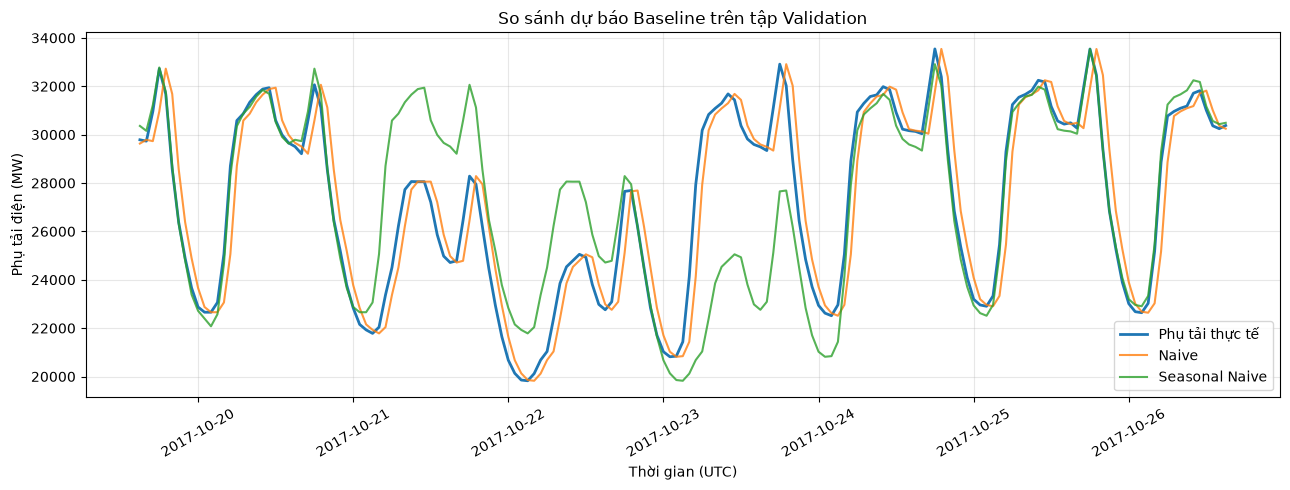

In [34]:

import matplotlib.pyplot as plt

# 1. Hàm tính các chỉ số đánh giá
def tinh_chi_so(thuc_te, du_bao):
    thuc_te = np.asarray(thuc_te, dtype=float)
    du_bao = np.asarray(du_bao, dtype=float)

    sai_so = thuc_te - du_bao

    rmse = np.sqrt(np.mean(sai_so ** 2))
    mae = np.mean(np.abs(sai_so))

    # MAPE chỉ tính tại các điểm có giá trị thực khác 0
    hop_le_mape = thuc_te != 0
    mape = (
        np.mean(
            np.abs(sai_so[hop_le_mape] / thuc_te[hop_le_mape])
        ) * 100
        if hop_le_mape.any() else np.nan
    )

    return rmse, mae, mape


# 2. Đánh giá hai phương pháp trên cùng tập thời điểm
bang_danh_gia = []

for ten, cot_du_bao in [
    ("Naive", "naive"),
    ("Seasonal Naive", "seasonal_naive")
]:
    rmse, mae, mape = tinh_chi_so(
        ket_qua_baseline_val["thuc_te"],
        ket_qua_baseline_val[cot_du_bao]
    )

    bang_danh_gia.append({
        "Mô hình": ten,
        "RMSE (MW)": rmse,
        "MAE (MW)": mae,
        "MAPE (%)": mape
    })

bang_danh_gia = pd.DataFrame(bang_danh_gia)

print("=== SO SÁNH BASELINE ===")
display(bang_danh_gia.round(3))

print(
    "Số target bằng 0, không dùng để tính MAPE:",
    (ket_qua_baseline_val["thuc_te"] == 0).sum()
)

# 3. Trực quan hóa 7 ngày đầu của Validation
bat_dau = ket_qua_baseline_val.index.min()
du_lieu_7_ngay = ket_qua_baseline_val.loc[
    bat_dau:bat_dau + pd.Timedelta(days=7)
]

plt.figure(figsize=(13, 5))

plt.plot(
    du_lieu_7_ngay.index,
    du_lieu_7_ngay["thuc_te"],
    label="Phụ tải thực tế",
    linewidth=2
)

plt.plot(
    du_lieu_7_ngay.index,
    du_lieu_7_ngay["naive"],
    label="Naive",
    alpha=0.8
)

plt.plot(
    du_lieu_7_ngay.index,
    du_lieu_7_ngay["seasonal_naive"],
    label="Seasonal Naive",
    alpha=0.8
)

plt.title("So sánh dự báo Baseline trên tập Validation")
plt.xlabel("Thời gian (UTC)")
plt.ylabel("Phụ tải điện (MW)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# PHASE 7 - VAR

# PHASE 8 - XGBOOST

# PHASE 9 - LSTM

# PHASE 10 - Basktesting & Evalution
